In [55]:
import pandas as pd
import numpy as np
import re

import nltk
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix


In [56]:
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

# upload dataset from system

from google.colab import files
uploaded=files.upload()

import io
file_name=list(uploaded.keys())[0]
# Added comment='#' to ignore metadata/comments at the top of the CSV file
df=pd.read_csv(io.BytesIO(uploaded[file_name]), comment='#')
print(df.head())

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


Saving sentiment_data.csv to sentiment_data (3).csv
    id                                               text sentiment  \
0  1.0  Absolutely love this product! It exceeded all ...  positive   
1  2.0  The service was okay, nothing special. Deliver...   neutral   
2  3.0  Terrible experience! The product arrived damag...  negative   
3  4.0  This is the best purchase I've made this year!...  positive   
4  5.0  Received the package today. It looks decent bu...   neutral   

   Unnamed: 3  Unnamed: 4  
0         NaN         NaN  
1         NaN         NaN  
2         NaN         NaN  
3         NaN         NaN  
4         NaN         NaN  


In [57]:
# Remove unnecessary unnamed columns
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

# Keep only required columns
df = df[['id', 'text', 'sentiment']]

# Remove empty rows
df = df.dropna(subset=['text', 'sentiment'])

# Clean column names
df.columns = df.columns.str.strip()

print(df.head())

    id                                               text sentiment
0  1.0  Absolutely love this product! It exceeded all ...  positive
1  2.0  The service was okay, nothing special. Deliver...   neutral
2  3.0  Terrible experience! The product arrived damag...  negative
3  4.0  This is the best purchase I've made this year!...  positive
4  5.0  Received the package today. It looks decent bu...   neutral


In [58]:
# Check the data set

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSentiment Distribution:")
print(df['sentiment'].value_counts())



Dataset Shape: (50, 3)

Column Names:
['id', 'text', 'sentiment']

Missing Values:
id           0
text         0
sentiment    0
dtype: int64

Sentiment Distribution:
sentiment
positive    17
neutral     17
negative    16
Name: count, dtype: int64


In [59]:
# Preprocess the dataset

import nltk
import re

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words('english'))

# Keep important negative words
stop_words -= {'not', 'no', 'nor'}

lemmatizer = WordNetLemmatizer()


def preprocess_text(text):

    text = str(text).lower()

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Remove punctuation and special characters
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Tokenization
    words = text.split()

    # Remove stopwords and perform lemmatization
    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    return ' '.join(words)


df['cleaned_text'] = df['text'].apply(preprocess_text)

print(df[['text', 'cleaned_text']].head())

                                                text  \
0  Absolutely love this product! It exceeded all ...   
1  The service was okay, nothing special. Deliver...   
2  Terrible experience! The product arrived damag...   
3  This is the best purchase I've made this year!...   
4  Received the package today. It looks decent bu...   

                                        cleaned_text  
0  absolutely love product exceeded expectation q...  
1  service okay nothing special delivery time pac...  
2  terrible experience product arrived damaged cu...  
3  best purchase made year feature amazing work e...  
4  received package today look decent tried yet u...  


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [60]:
# Separate Features and labels
x=df['cleaned_text']
y=df['sentiment']
print("Features: ",x.head())
print("\nLabels: ",y.head())

Features:  0    absolutely love product exceeded expectation q...
1    service okay nothing special delivery time pac...
2    terrible experience product arrived damaged cu...
3    best purchase made year feature amazing work e...
4    received package today look decent tried yet u...
Name: cleaned_text, dtype: object

Labels:  0    positive
1     neutral
2    negative
3    positive
4     neutral
Name: sentiment, dtype: object


In [61]:
# Split training and testing data 80-20
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(x_train))
print("Testing Samples:", len(x_test))

print("\nTraining Sentiments:")
print(y_train.value_counts())

print("\nTesting Sentiments:")
print(y_test.value_counts())

Training Samples: 40
Testing Samples: 10

Training Sentiments:
sentiment
positive    14
negative    13
neutral     13
Name: count, dtype: int64

Testing Sentiments:
sentiment
neutral     4
negative    3
positive    3
Name: count, dtype: int64


In [62]:
# TF-IDF

from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(max_features=5000)
x_train_tfidf = tfidf.fit_transform(x_train)
x_test_tfidf = tfidf.transform(x_test)
print("Training TF-IDF Shape:", x_train_tfidf.shape)
print("Testing TF-IDF Shape:", x_test_tfidf.shape)

Training TF-IDF Shape: (40, 262)
Testing TF-IDF Shape: (10, 262)


In [63]:
# Multinomial naive bayes model train

from sklearn.naive_bayes import MultinomialNB
nb_model = MultinomialNB()
nb_model.fit(x_train_tfidf, y_train)
print("Naive bayes model trained successfully.")

Naive bayes model trained successfully.


In [64]:
# Logistic regression model train

from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(x_train_tfidf, y_train)
print("Logistic regression model trained successfully.")


Logistic regression model trained successfully.


In [65]:
# Evaluate naive bayes model

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

nb_predictions = nb_model.predict(X_test_tfidf)

nb_accuracy = accuracy_score(
    y_test,
    nb_predictions
)

print("Naive Bayes Accuracy:",
      nb_accuracy * 100, "%")

print("\nClassification Report:")

print(classification_report(
    y_test,
    nb_predictions,
    zero_division=0
))

Naive Bayes Accuracy: 90.0 %

Classification Report:
              precision    recall  f1-score   support

    negative       0.75      1.00      0.86         3
     neutral       1.00      0.75      0.86         4
    positive       1.00      1.00      1.00         3

    accuracy                           0.90        10
   macro avg       0.92      0.92      0.90        10
weighted avg       0.93      0.90      0.90        10



In [66]:
# Evaluate the logistic regression model

lr_predictions = lr_model.predict(x_test_tfidf)

lr_accuracy = accuracy_score(
    y_test,
    lr_predictions
)

print("Logistic Regression Accuracy:",
      lr_accuracy * 100, "%")

print("\nClassification Report:")

print(classification_report(
    y_test,
    lr_predictions,
    zero_division=0
))

Logistic Regression Accuracy: 90.0 %

Classification Report:
              precision    recall  f1-score   support

    negative       0.75      1.00      0.86         3
     neutral       1.00      0.75      0.86         4
    positive       1.00      1.00      1.00         3

    accuracy                           0.90        10
   macro avg       0.92      0.92      0.90        10
weighted avg       0.93      0.90      0.90        10



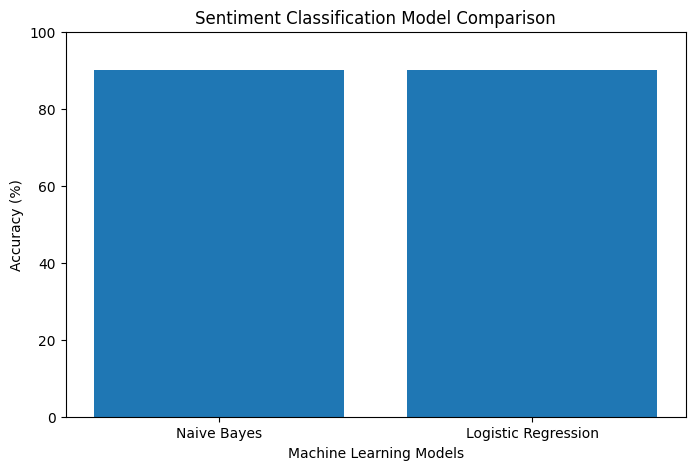

In [67]:
# Compare both models

import matplotlib.pyplot as plt

models = ['Naive Bayes', 'Logistic Regression']

accuracies = [
    nb_accuracy * 100,
    lr_accuracy * 100
]

plt.figure(figsize=(8, 5))

plt.bar(models, accuracies)

plt.title('Sentiment Classification Model Comparison')

plt.xlabel('Machine Learning Models')

plt.ylabel('Accuracy (%)')

plt.ylim(0, 100)

plt.show()

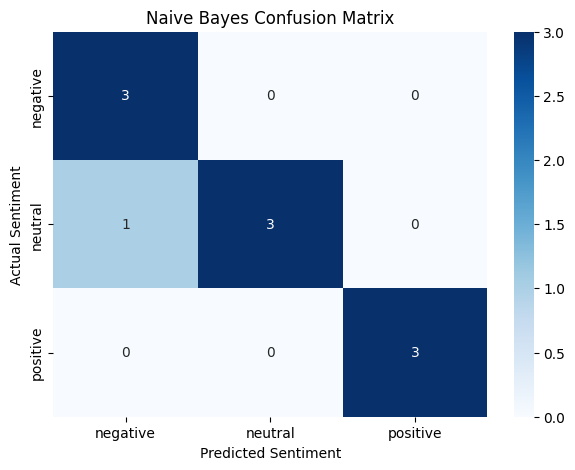

In [68]:
# Confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(
    y_test,
    nb_predictions,
    labels=nb_model.classes_
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=nb_model.classes_,
    yticklabels=nb_model.classes_
)

plt.title('Naive Bayes Confusion Matrix')

plt.xlabel('Predicted Sentiment')

plt.ylabel('Actual Sentiment')

plt.show()

In [69]:
# Function for user own reviews
def predict_sentiment(review):

    cleaned = preprocess_text(review)

    vector = tfidf.transform([cleaned])

    prediction = nb_model.predict(vector)

    print("Customer Review:", review)

    print("Predicted Sentiment:", prediction[0])


predict_sentiment("This product is absolutely amazing!")

predict_sentiment("The quality is very poor.")

predict_sentiment("The product is average.")

user_review = input("Enter your customer review: ")

predict_sentiment(user_review)


Customer Review: This product is absolutely amazing!
Predicted Sentiment: positive
Customer Review: The quality is very poor.
Predicted Sentiment: negative
Customer Review: The product is average.
Predicted Sentiment: neutral
Enter your customer review: love this product
Customer Review: love this product
Predicted Sentiment: positive


In [70]:
# Actual and predicted results

results = pd.DataFrame({
    'Actual Sentiment': y_test.values,
    'Predicted Sentiment': nb_predictions
})

print(results)

  Actual Sentiment Predicted Sentiment
0          neutral             neutral
1         negative            negative
2         positive            positive
3          neutral             neutral
4         negative            negative
5         positive            positive
6         positive            positive
7          neutral            negative
8         negative            negative
9          neutral             neutral
